In [1]:
import sys, os
#import pandas as pd

#from src.statistics_utils import summary_statistics
#from src.regression_utils import train_regression
#from src.health_analyzer import HealthAnalyzer
sys.path.append(os.path.abspath(".."))

#from src.io_utils import *


#df = pd.read_csv("data/health_study_dataset.csv")

In [2]:
print(os.path.abspath(".."))

c:\Users\rvmad\Desktop\Exam_HS


In [3]:
from src.statistics_utils import summary_statistics
from src.regression_utils import train_regression
from src.health_analyzer import HealthAnalyzer

# Summary Statistics

In [4]:
import pandas as pd

df = pd.read_csv("../data/health_study_dataset.csv")

summary_statistics(df)

,age,height,weight,systolic_bp,cholesterol
mean,49.42625,171.84925,73.413,149.178625,4.92915
median,50.00000,171.35000,73.200,149.400000,4.97000
min,18.00000,144.40000,33.700,106.800000,2.50000
max,90.00000,200.40000,114.400,185.900000,7.88000


# Linear Regression

In [5]:
model = train_regression(df)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: 109.49908144566373
Coefficients: [0.53892763 0.17765752]


# Health Analyzer Class

In [6]:
analyzer = HealthAnalyzer(df)

print("Mean BP:", analyzer.calculate_mean_bp)
print("Disease Rate:", analyzer.disease_rate)

Mean BP: <bound method HealthAnalyzer.calculate_mean_bp of <src.health_analyzer.HealthAnalyzer object at 0x00000253119FDA90>>
Disease Rate: <bound method HealthAnalyzer.disease_rate of <src.health_analyzer.HealthAnalyzer object at 0x00000253119FDA90>>


# Graphs 

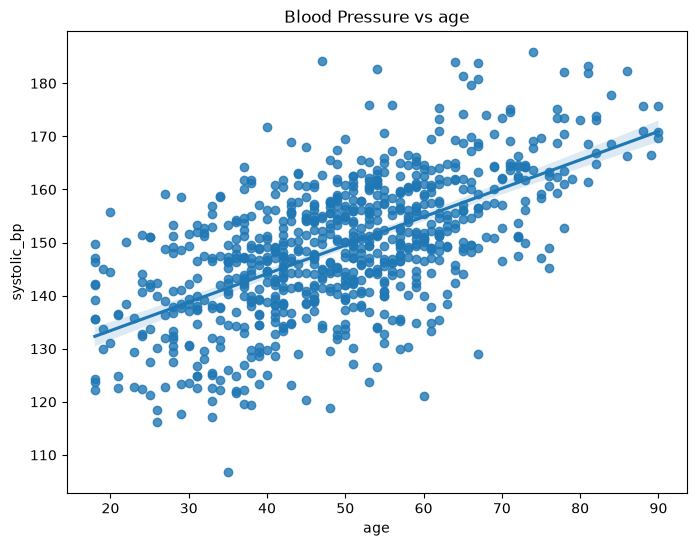

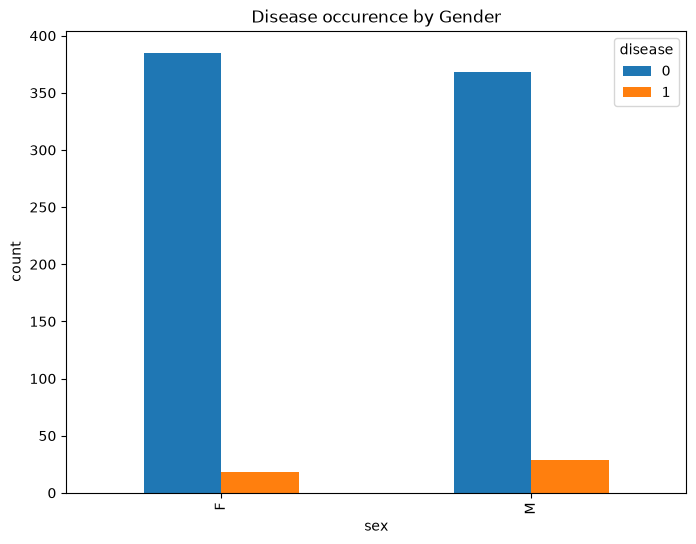

In [7]:
analyzer.plot_bp_vs_age()

analyzer.plot_disease_by_gender()

# Object-oriented Design
To improve code organization and reusability, a health analyzer class was created.
This class encapsulates
    - Calculating Mean Blood Pressure
    - Calculating disease Prevalence
    - Plotting blood pressure versus age
    - Visualising disease occurence by gender
Reusable functions placed in separate modules to folllow good software practices and reduce code duplication    

# linear Algebra In Practice
y=mx+c
linear regression is based on linear algebra
predict systolic blood pressure using age and weight

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler




def train_bp_regression(df):
    
    X = df[['age', 'weight']]
    y = df['systolic_bp']

    model = LinearRegression()
    model.fit(X, y)

    return model, X, y


In [9]:
model, X, y = train_bp_regression(df)

print("Intercept: ", model.intercept_)
print("Age coefficient: ", model.coef_[0])
print("weigth coefficient: ", model.coef_[1])

Intercept:  109.49908144566373
Age coefficient:  0.5389276325169825
weigth coefficient:  0.17765752193267906


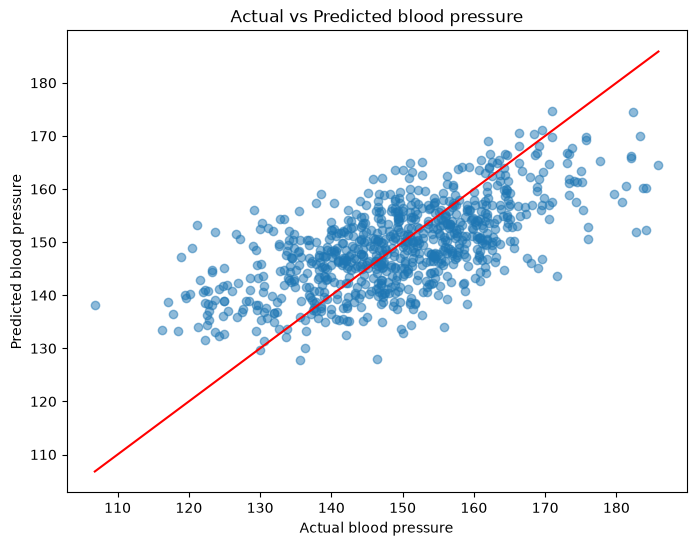

In [10]:
predictions = model.predict(X)

plt.figure(figsize=(8,6))
plt.scatter(y, predictions, alpha=0.5)
plt.xlabel("Actual blood pressure")
plt.ylabel("Predicted blood pressure")
plt.title("Actual vs Predicted blood pressure")
plt.plot([y.min(), y.max()],
         [y.min(), y.max()],
         color="red")
plt.show()

#PCA (prinicipal component analysis)to find patterns in the data 
Linear Algebra demonstrations with Matrices
^Y= b0+b1X

In [11]:
X_matrix= np.column_stack([
    np.ones(len(df)),
    df["age"],
    df["weight"]
])

beta = np.concatenate([[model.intercept_], model.coef_])

y_hat = X_matrix @ beta

print(y_hat[:10])

[151.90782144 151.86603653 155.89926007 164.84178628 152.78390057
 146.47705855 163.58637294 151.52302941 146.64866155 152.71323536]


#PCA uses given vectors and matrix decomposition to reduce dimensionality and identify patterns in data
Variables used :
age 
weight 
height
systolic_bp
cholestrol

In [12]:
def perform_pca(df):

    features = [
        'age',
        'height',
        'weight',
        'systolic_bp',
        'cholesterol'
    ]

    X = df[features]

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    pca = PCA(n_components=2)
    pca_data = pca.fit_transform(X_scaled)

    return pca, pca_data


In [13]:
pca, pca_data = perform_pca(df)

print("Explained variance ratio")
print("pca.explained_variance_ratio_")

Explained variance ratio
pca.explained_variance_ratio_


# PCA Visualisation

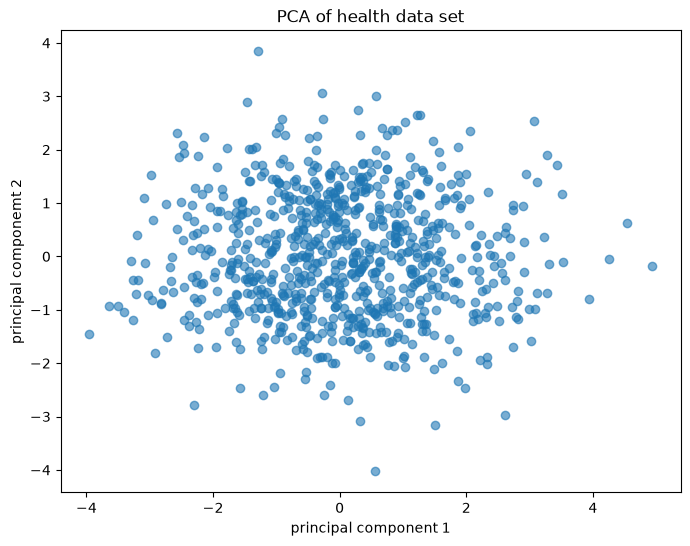

In [14]:
plt.figure(figsize=(8,6))

plt.scatter(
    pca_data[:,0],
    pca_data[:,1],
    alpha=0.6
)

plt.xlabel("principal component 1")
plt.ylabel("principal componemt 2")
plt.title("PCA of health data set")

plt.show()

#Extended Analysis 1: Blood pressure vs Age
Relationship between age and blood presssure
To check whether older people have higher systolic blood pressure

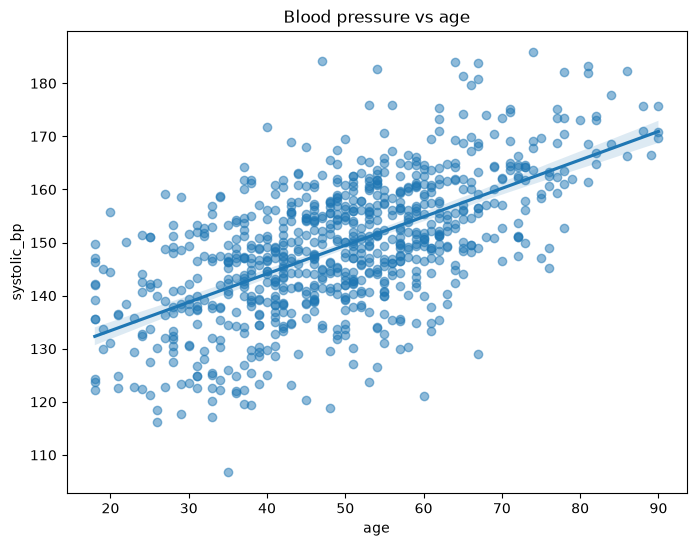

In [15]:
plt.figure(figsize=(8,6))

sns.regplot(
    data=df,
    x = "age",
    y = "systolic_bp",
    scatter_kws={"alpha":0.5}
)

plt.title("Blood pressure vs age")
plt.show()

#positive slope that means blood pressure increases with age 

#Extended Analysis Disease occurence by gender

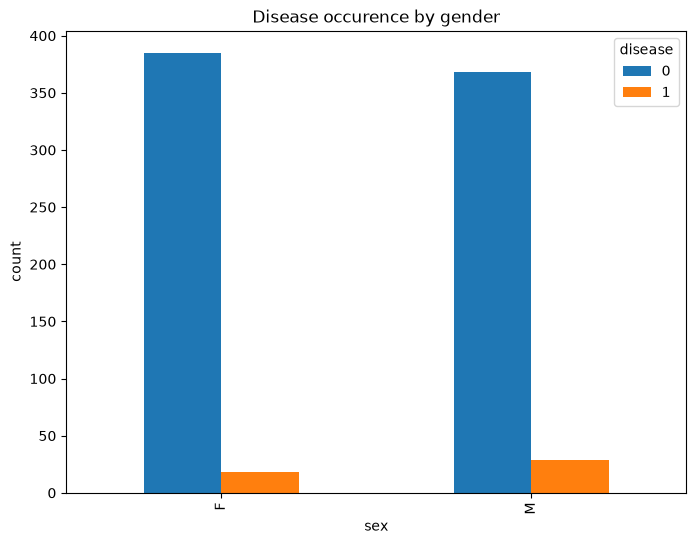

In [16]:
disease_gender = pd.crosstab(
    df["sex"],
    df["disease"]
)

disease_gender.plot(
    kind = "bar",
    figsize=(8,6)
)

plt.title("Disease occurence by gender")
plt.ylabel("count")
plt.show()

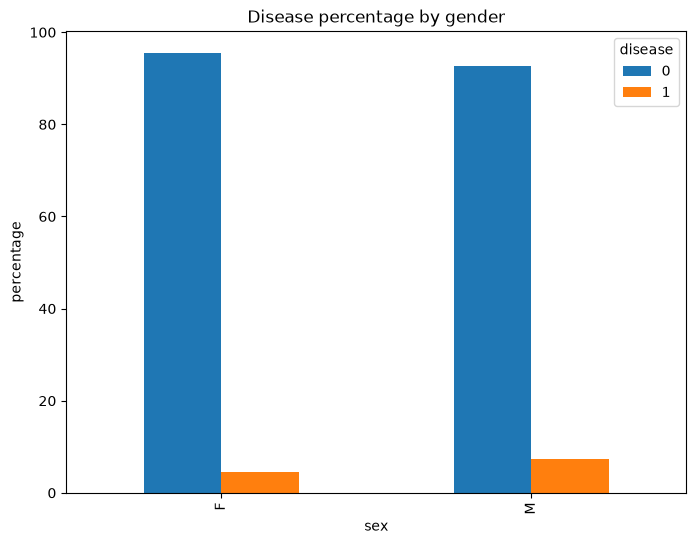

In [17]:
disease_percent = pd.crosstab(
    df["sex"],
    df["disease"],
    normalize="index"
)*100

disease_percent.plot(
    kind = "bar",
    figsize=(8,6)
)

plt.title("Disease percentage by gender")
plt.ylabel("percentage")
plt.show()

#Corelation Heatmap
Deeper understanding of visualisations

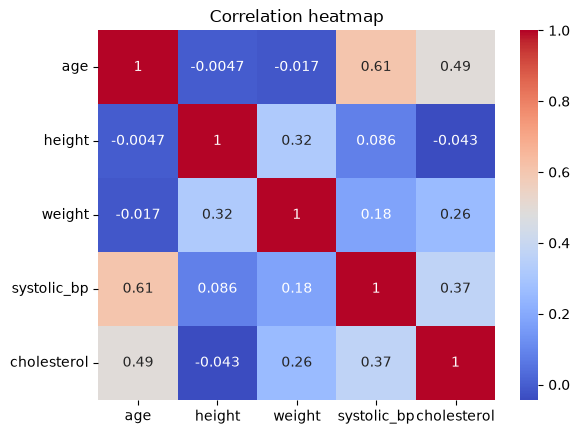

In [18]:
plt.Figure(figsize=(8,6))

numeric_cols = [
    "age",
    "height",
    "weight",
    "systolic_bp",
    "cholesterol"
]

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation heatmap")
plt.show()